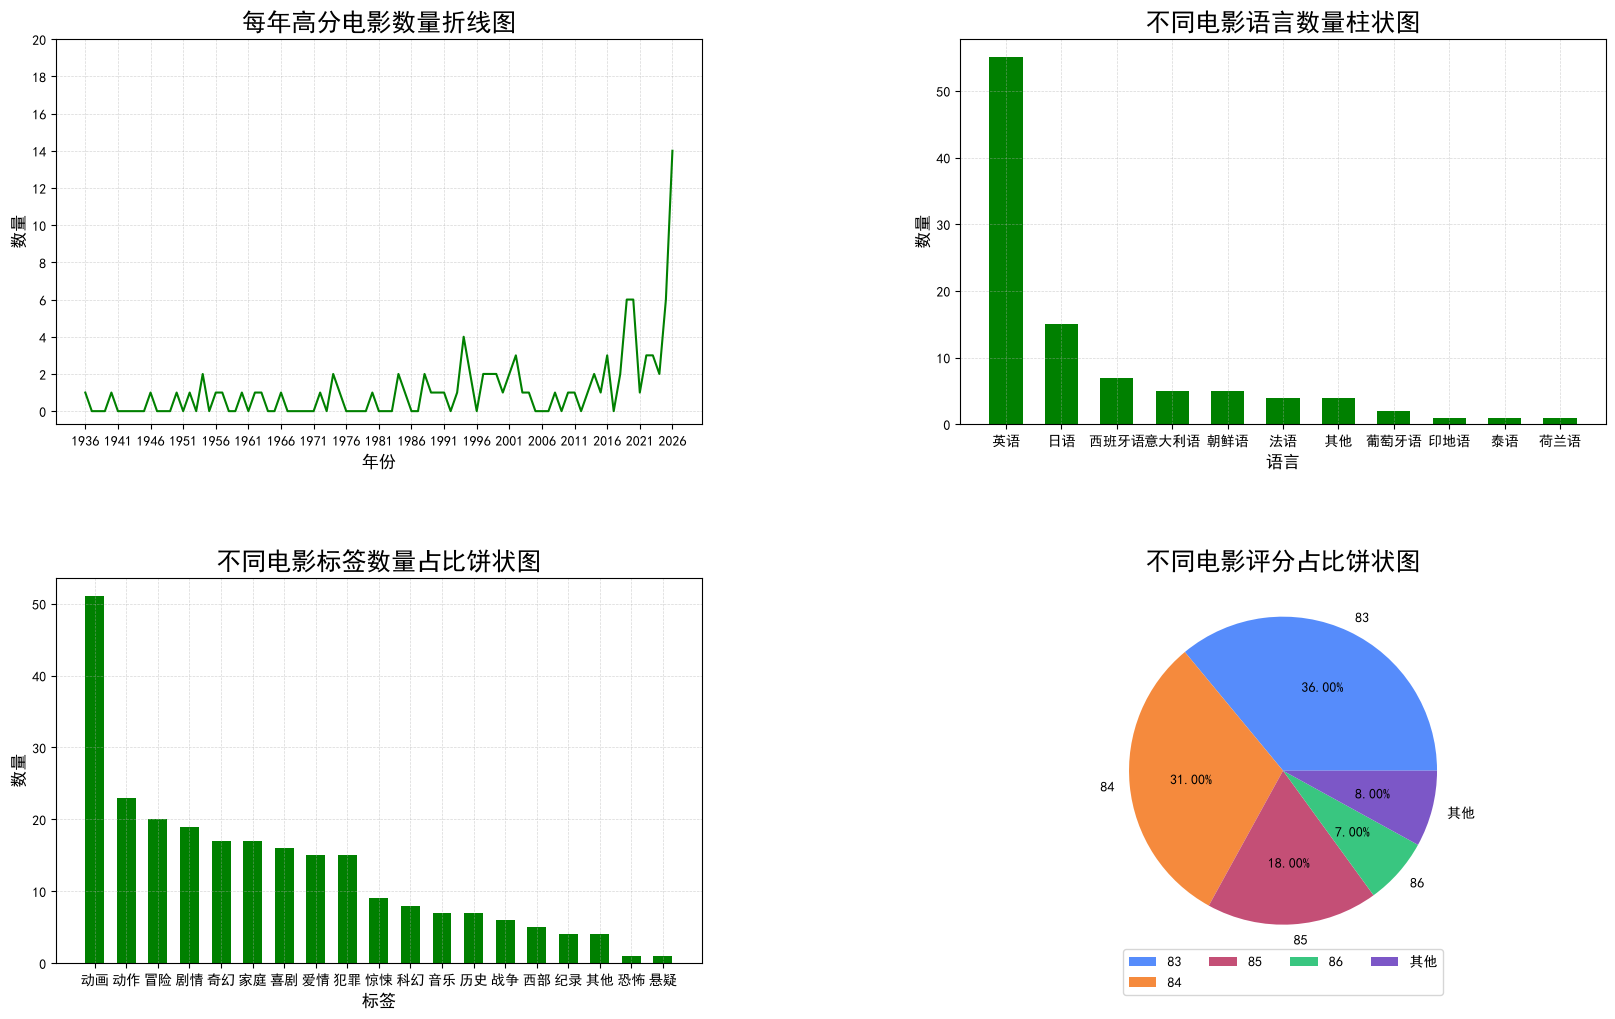

In [88]:
from matplotlib.axes import Axes
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib.lines import lineStyles
from matplotlib.patches import bbox_artist

#展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']
#读取数据
data=pd.read_csv('csv_file/All_movies.csv')
#数据预处理
data['上映时间']=data['上映时间'].fillna('----------')
data['电影时长']=data['电影时长'].replace(0,'暂无数据')
year_count=data.groupby('电影年份')['电影年份'].count()#以电影年份为标签进行分组，输出内容为键值对类型
min_year=year_count.index.min()
max_year=year_count.index.max()
x=[i for i in range(min_year,max_year+1)]
y=[year_count.get(i,0) for i in x]
#创建子图
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(20,12))
axes1:Axes=axes[0,0]
axes2:Axes=axes[0,1]
axes3:Axes=axes[1,0]
axes4:Axes=axes[1,1]
fig.subplots_adjust(wspace=0.4,hspace=0.4)#调整子图之间的间距
#绘制折线图
axes1.plot(x,y,color='green')
axes1.set_title('每年高分电影数量折线图',fontsize=18)#设置图的标题
axes1.set_xlabel('年份',fontsize=12)#设置横坐标标签
axes1.set_ylabel('数量',fontsize=12) #设置纵坐标标签
axes1.set_xticks(x[::5])#设置横坐标
axes1.set_yticks([i for i in range(0,21,2)])#设置纵坐标
axes1.grid(linestyle='--',alpha=0.5)
#数据预处理
data['电影语言']=data['电影语言'].replace('-','其他')
lau_count=data.groupby('电影语言')['电影语言'].count().sort_values(ascending=False)
#定义x,y轴
x_lau=lau_count.index.tolist()
y_lau=lau_count.values.tolist()
#绘制柱状图
axes2.bar(x_lau,y_lau,color='green',width=0.6)
axes2.set_title('不同电影语言数量柱状图',fontsize=18)
axes2.set_xlabel('语言',fontsize=12)
axes2.set_ylabel('数量',fontsize=12)
axes2.grid(linestyle='--',alpha=0.5)
#防止文字排版密集，若要旋转文字可启用该项
# axes2.tick_params(axis='x',rotation=90)
#准备统计对比不同类型的电影数量
data['电影标签']=data['电影标签'].fillna('其他')#数据预处理
tags_count={}
tags=data['电影标签'].str.split(",")
#把标签所出现的次数统计到字典中
for tag in tags:
    for t in tag:
        if t in tags_count:
            tags_count[t]+=1
        else:
            tags_count[t]=1
x_tags=list(tags_count.keys())
y_tags=list(tags_count.values())
#若要对数据排序，启用此项
y_tags.sort(reverse=True)
#绘制饼状图
axes3.bar(x_tags,y_tags,color='green',width=0.6)
axes3.set_title('不同电影标签数量占比饼状图',fontsize=18)
axes3.set_xlabel('标签',fontsize=12)
axes3.set_ylabel('数量',fontsize=12)
axes3.grid(linestyle='--',alpha=0.5)

#数据处理
rate_count=data.groupby('电影评分')['电影评分'].count()
#取出数值小于等于3%归类于其他
over3=rate_count.loc[rate_count>rate_count.sum()*0.03]
less3=rate_count[rate_count<=rate_count.sum()*0.03]
#将其命名为'其他'，然后添加到总over3中
if less3.shape[0]>0:
    over3['其他']=less3.sum()
rate_=over3.index.tolist()#将评分转换为列表
qua_=over3.values.tolist()#对应评分数量转化为列表
#绘制饼状图
axes4.pie(qua_,labels=rate_,autopct='%1.2f%%')
axes4.set_title('不同电影评分占比饼状图',fontsize=18)
axes4.legend(loc='lower center',ncol=4,bbox_to_anchor=(0.5,-0.1))

#保存图片
os.makedirs('Start/Pic',exist_ok=True)
plt.savefig('Start/Pic/movie_analysis.png')
plt.show()